## Testceller: Support Vector Machines

#### Imports

In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay



#### Ingestion

In [97]:
df = pd.read_csv('stroke_risk_prediction_dataset.csv')

df.dropna()
drop_list = ["Patient_ID"]
dummy_list = []

for c in df.columns:
    if type(df[c][0]) == str:
        if len(df[c].unique())>3:
            drop_list.append(c)
        else:
            if c != 'Stroke_Risk':
                dummy_list.append(c)

df.drop(columns=drop_list)

,Age,Gender,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Blood_Glucose,HbA1c,...,Previous_TIA,Atrial_Fibrillation,Chronic_Kidney_Disease,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,Doctor_Consultation_Needed,Stroke_Risk
0,80.0,Male,145.2,69.3,32.9,112,82,109,132.2,5.2,...,No,No,No,NaN,79.0,Urban,High,47,Yes,Moderate
1,37.0,Female,188.6,110.8,31.1,137,76,59,187.5,7.1,...,No,No,Yes,0.6,48.0,Rural,Medium,40,Yes,Moderate
2,85.0,Female,175.5,103.7,33.7,108,105,89,196.4,8.0,...,No,No,No,1.7,114.0,Rural,Medium,76,Yes,High
3,44.0,Other,161.3,50.2,19.3,126,73,88,209.1,7.3,...,No,No,Yes,1.5,101.0,Rural,Low,40,Yes,Moderate
4,52.0,Female,162.8,103.6,39.1,115,60,70,88.6,7.1,...,No,No,No,7.1,55.0,Rural,Medium,38,Yes,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,22.0,Male,171.7,113.4,38.5,139,78,81,107.8,9.2,...,No,No,No,3.2,41.0,Urban,Medium,40,No,Moderate
49996,61.0,Male,164.6,64.0,23.6,123,92,87,158.9,8.3,...,No,No,No,0.7,92.0,Rural,Medium,59,Yes,Moderate
49997,76.0,Female,148.9,56.4,25.4,153,93,95,143.3,8.3,...,No,No,No,0.7,31.0,Urban,High,64,Yes,Moderate
49998,31.0,Other,183.7,75.7,22.4,108,77,76,90.1,7.0,...,No,No,No,3.4,90.0,Rural,Low,26,No,Low


#### Preprocessing

In [98]:
n_data_points = 500
df_data = df.dropna().iloc[0:n_data_points].drop(columns=drop_list)

X_data = pd.get_dummies(df_data.iloc[:, 0:-1], columns=dummy_list)
y_data = df_data.iloc[:, -1]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_data)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_data, test_size=0.2, random_state=67, stratify=y_data)

#### Configuration of SVM

In [99]:
svm = SVC(decision_function_shape = 'ovr', probability=True)
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)
y_proba = svm.predict_proba(X_test)

/Users/rikard/anaconda3/envs/cb1020_env/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


#### Evaluation

In [100]:
low, moderate, high = 0, 0, 0
for i in y_test:
    if i == 'Moderate':
        moderate += 1
    if i == 'Low':
        low += 1
    if i == 'High':
        high += 1

print(f'low: {low} \nmoderate: {moderate} \nhigh: {high}')
    

low: 9 
moderate: 68 
high: 23


In [101]:
low, moderate, high = 0, 0, 0
for i in y_pred:
    if i == 'Moderate':
        moderate += 1
    if i == 'Low':
        low += 1
    if i == 'High':
        high += 1

print(f'low: {low} \nmoderate: {moderate} \nhigh: {high}')
    

low: 4 
moderate: 83 
high: 13


In [102]:
print(sklearn.metrics.classification_report(y_test, y_pred, labels=np.sort(np.unique(y_data)))
)

              precision    recall  f1-score   support

        High       1.00      0.57      0.72        23
         Low       1.00      0.44      0.62         9
    Moderate       0.82      1.00      0.90        68

    accuracy                           0.85       100
   macro avg       0.94      0.67      0.75       100
weighted avg       0.88      0.85      0.83       100



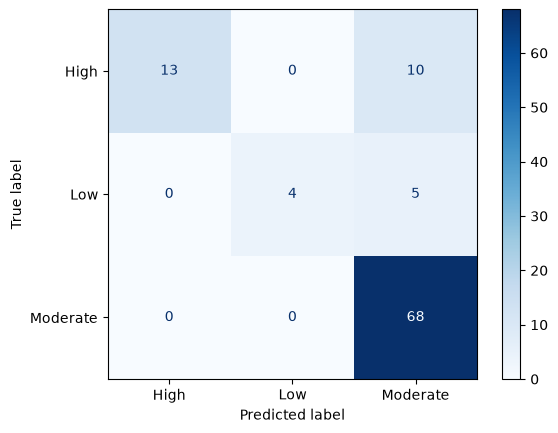

In [103]:
cm = sklearn.metrics.confusion_matrix(y_test, y_pred)
CM = sklearn.metrics.ConfusionMatrixDisplay(cm, display_labels = np.sort(np.unique(y_data)))
CM.plot(cmap=plt.cm.Blues)

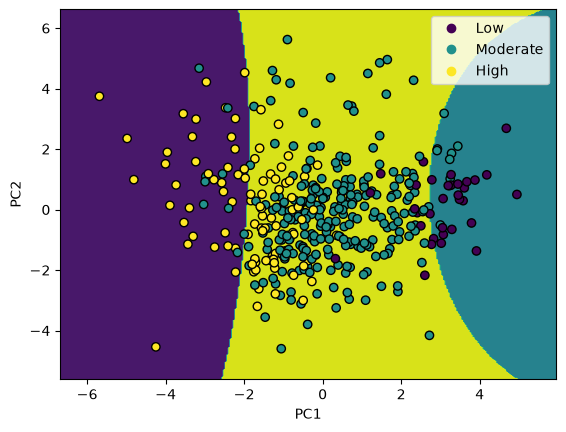

In [104]:
pca = PCA(n_components=2)
X_train_2D = pca.fit_transform(X_train)

xx, yy = np.meshgrid(np.linspace(X_train_2D[:, 0].min() - 1, X_train_2D[:, 0].max() + 1, 300), 
                     np.linspace(X_train_2D[:, 1].min() - 1, X_train_2D[:, 1].max() + 1, 300)
                    )

grid_2D = np.c_[xx.ravel(), yy.ravel()]
grid_58D = pca.inverse_transform(grid_2D)


Z = svm.decision_function(grid_58D).argmax(axis=1).reshape(xx.shape)

y_train_colors = []
for i in y_train:
    if i == 'Low':
        y_train_colors.append(0)
    if i == 'Moderate':
        y_train_colors.append(1)
    if i == 'High':
        y_train_colors.append(2)

plt.contourf(xx, yy, Z)
scatter = plt.scatter(X_train_2D[:,0], X_train_2D[:,1], c=y_train_colors, edgecolor='k')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.legend(handles=scatter.legend_elements()[0], labels=['Low', 'Moderate', 'High'])

In [105]:
df.groupby('Stroke_Risk')['Stroke_Risk_Score'].agg(['min', 'max', 'mean'])

,min,max,mean
Stroke_Risk,,,
High,65,100,73.134082
Low,2,34,28.836892
Moderate,35,64,50.967622


In [106]:
from Test_Modul import jockiboi

jockiboi(3)

array([1., 1., 1.])